# Covariáveis por zona OD — % de pessoas negras e distância às estações

Constrói duas variáveis das zonas OD 2023 do município de São Paulo, para os gráficos do sinal
Tarifa Zero (`04_correlatos/correlatos_sinal_zona.ipynb`):

1. **% de pessoas negras** (pretas + pardas) — Censo 2022, Universo, agregado de setor para zona.
2. **Distância euclidiana** do centroide da zona à estação de trem/metrô mais próxima — estações
   extraídas do GTFS da SPTrans/Metrô/CPTM. A distância **por rede** (r5py) é calculada à parte em
   `09_cria_base_dist_rede_estacao.ipynb`, a partir das estações gravadas aqui.

O universo são as **343 zonas** do município (`NumeroMuni == 36`), não só as com demanda — o corte
por base mínima é feito no notebook de comparação.

Saídas em `../outputs/01/`: `covariaveis_zona.parquet` e `estacoes_trilho.gpkg`.

## Seção 0 — imports e configuração

In [1]:
import zipfile
from pathlib import Path

import duckdb
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CRS_WGS84 = 4326
CRS_LOCAL_UTM = 31983   # SIRGAS 2000 / UTM zone 23S
CD_UF = "35"
CD_MUN_SP = "3550308"   # codigo IBGE do municipio de Sao Paulo (prefixo do CD_SETOR)
COD_MUNI_SP = 36        # NumeroMuni de Sao Paulo em Zonas_2023.shp

DIR_CENSO = Path("../Dados/censo_2022")
CSV_COR_RACA = DIR_CENSO / "Agregados_por_setores_cor_ou_raca_BR.csv"
GPKG_SETORES = DIR_CENSO / "SP_setores_CD2022.gpkg"
SHP_ZONAS = Path("../Dados/pacote-anexos-od_10-02-25_0/002_Site Metro Mapas/Shape/Zonas_2023.shp")
GTFS = Path("../Dados/r5/sao_paulo/mdb-8-202607140108.zip")
DIR_SAIDA = Path("../outputs/01")

# Colunas do agregado de cor ou raca (total por categoria, Universo). A ordem foi conferida na
# Secao 1: cada categoria e a soma de homens + mulheres (colunas seguintes).
COLUNAS_COR = {"V01317": "branca", "V01318": "preta", "V01319": "amarela", "V01320": "parda", "V01321": "indigena"}

In [2]:
zonas = gpd.read_file(SHP_ZONAS).to_crs(CRS_LOCAL_UTM)
zonas = zonas[zonas["NumeroMuni"] == COD_MUNI_SP][["NumeroZona", "NomeZona", "geometry"]].reset_index(drop=True)
print(f"zonas do municipio de Sao Paulo: {len(zonas)}")

zonas do municipio de Sao Paulo: 343


## Seção 1 — % de pessoas negras por zona

O agregado do Censo traz, por setor censitário, o total de moradores por cor ou raça. Como o setor é
pequeno, ele vai inteiro para a zona onde cai o seu ponto representativo (mesmo critério do notebook
`06_cria_base_renda_zona.ipynb`), e a zona soma os seus setores — diferente da renda, aqui **não passa
por AP**, porque a variável existe por setor.

`pct_negros = (pretas + pardas) / (branca + preta + amarela + parda + indígena)`. O IBGE omite
(`X`) as células muito pequenas; elas entram como zero, e a Seção 1 mede o tamanho dessa omissão.

In [3]:
num = lambda c: f"TRY_CAST({c} AS DOUBLE)"
sql_cor = ", ".join(f"{num(c)} AS {nome}" for c, nome in COLUNAS_COR.items())
sql_omitido = " + ".join(f"({c} = 'X')::INT" for c in COLUNAS_COR)
cor = duckdb.sql(f"""
    SELECT CD_SETOR, {sql_cor}, {sql_omitido} AS n_omitidas,
           {num("V01322")} AS branca_h, {num("V01327")} AS branca_m
    FROM read_csv('{CSV_COR_RACA.as_posix()}', delim=';', all_varchar=true)
    WHERE CD_SETOR LIKE '{CD_UF}%'
""").df()
categorias = list(COLUNAS_COR.values())
cor["total_cor"] = cor[categorias].sum(axis=1)       # NaN (X) conta como zero
print(f"setores da UF: {len(cor):,} | com alguma celula omitida: {(cor['n_omitidas'] > 0).mean():.1%}")

# Conferencia da ordem das colunas: branca = homens + mulheres, nos setores sem omissao.
ok = cor.dropna(subset=["branca", "branca_h", "branca_m"])
print(f"V01317 == V01322 + V01327 em {(ok['branca'] == ok['branca_h'] + ok['branca_m']).mean():.1%} dos setores sem omissao")

# Setor -> zona pelo ponto representativo
setores = gpd.read_file(GPKG_SETORES, columns=["CD_SETOR"], bbox=tuple(zonas.to_crs(4674).total_bounds)).to_crs(CRS_LOCAL_UTM)
setores["geometry"] = setores.representative_point()
setor_zona = gpd.sjoin(setores, zonas[["NumeroZona", "geometry"]], predicate="within")[["CD_SETOR", "NumeroZona"]]
assert setor_zona["CD_SETOR"].is_unique, "setor em mais de uma zona"

base = setor_zona.merge(cor, on="CD_SETOR", how="left")
print(f"setores dentro das zonas de SP: {len(base):,} | sem dado de cor: {base['total_cor'].isna().sum()}")

setores da UF: 100,928 | com alguma celula omitida: 38.6%
V01317 == V01322 + V01327 em 100.0% dos setores sem omissao


setores dentro das zonas de SP: 27,301 | sem dado de cor: 412


In [4]:
zona_cor = base.groupby("NumeroZona")[categorias + ["total_cor"]].sum()
zona_cor["pct_negros"] = 100 * (zona_cor["preta"] + zona_cor["parda"]) / zona_cor["total_cor"].where(zona_cor["total_cor"] > 0)
zona_cor = zona_cor.rename(columns={"total_cor": "pop_cor"})

# Conferencia com o municipio: a media das zonas deve reproduzir o % do municipio inteiro (setores do
# CD_MUN_SP, sem passar pelas zonas); a diferenca e so de setores que nao caem em zona alguma.
mun = cor[cor["CD_SETOR"].str.startswith(CD_MUN_SP)]
pct_mun = 100 * (mun["preta"].sum() + mun["parda"].sum()) / mun["total_cor"].sum()
pct_zonas = 100 * (zona_cor["preta"].sum() + zona_cor["parda"].sum()) / zona_cor["pop_cor"].sum()
print(f"% negros no municipio (todos os setores): {pct_mun:.2f}% | nas zonas agregadas: {pct_zonas:.2f}% "
      f"| moradores: {mun['total_cor'].sum():,.0f} no municipio, {zona_cor['pop_cor'].sum():,.0f} nas zonas")
assert abs(pct_mun - pct_zonas) < 0.2

print(zona_cor["pct_negros"].describe().round(1).to_string())
assert zona_cor["pct_negros"].dropna().between(0, 100).all()

# Zonas sem moradores no Censo (parques, areas industriais...) ficam sem % -- nao ha pessoas para contar.
sem_morador = sorted(set(zonas["NumeroZona"]) - set(zona_cor.dropna(subset=["pct_negros"]).index))
print(f"\nzonas sem moradores no Censo (pct_negros = NaN): {len(sem_morador)} {sem_morador}")
zona_cor = zona_cor[["pop_cor", "pct_negros"]]

% negros no municipio (todos os setores): 43.51% | nas zonas agregadas: 43.51% | moradores: 11,426,760 no municipio, 11,426,760 nas zonas
count    340.0
mean      35.9
std       17.6
min        7.2
25%       18.9
50%       35.6
75%       51.6
max       72.9

zonas sem moradores no Censo (pct_negros = NaN): 3 [120, 143, 146]


## Seção 2 — estações de trem e metrô

As estações saem do GTFS: rotas com `route_type` 1 (Metrô) e 2 (CPTM) → viagens → paradas. Cada
parada é uma plataforma; uma estação de integração (Brás, Luz, Sé...) aparece uma vez por linha, o que
não altera a "estação mais próxima".

O feed é de julho/2026, mas **nenhuma estação dele foi aberta de 2023 em diante**: as aberturas mais
recentes são Jardim Colonial (Linha 15, 29/12/2021), Vila Sônia (Linha 4, 17/12/2021) e
Guarulhos-Cecap/Aeroporto-Guarulhos (Linha 13, 31/03/2018). Entram também as estações de municípios
vizinhos — a mais próxima de uma zona de borda pode estar do outro lado da divisa.

In [5]:
with zipfile.ZipFile(GTFS) as z:
    le = lambda nome, **k: pd.read_csv(z.open(nome), dtype=str, encoding="utf-8-sig", **k)
    rotas = le("routes.txt", usecols=["route_id", "route_type", "route_short_name"])
    viagens = le("trips.txt", usecols=["route_id", "trip_id"])
    paradas = le("stops.txt", usecols=["stop_id", "stop_name", "stop_lat", "stop_lon"])
    horarios = le("stop_times.txt", usecols=["trip_id", "stop_id"])

trilho = rotas[rotas["route_type"].isin(["1", "2"])].copy()
trilho["modo"] = trilho["route_type"].map({"1": "Metrô", "2": "CPTM"})
passagens = (horarios.merge(viagens, on="trip_id").merge(trilho[["route_id", "route_short_name", "modo"]], on="route_id")
             [["stop_id", "route_short_name", "modo"]].drop_duplicates())
estacoes = (
    passagens.groupby("stop_id").agg(linha=("route_short_name", lambda s: ", ".join(sorted(s))), modo=("modo", "first"))
    .reset_index().merge(paradas, on="stop_id")
)
estacoes = gpd.GeoDataFrame(
    estacoes.rename(columns={"stop_name": "estacao"}).drop(columns=["stop_lat", "stop_lon"]),
    geometry=gpd.points_from_xy(estacoes["stop_lon"].astype(float), estacoes["stop_lat"].astype(float)),
    crs=CRS_WGS84,
).to_crs(CRS_LOCAL_UTM)

print(f"paradas de trilho: {len(estacoes)} | nomes distintos: {estacoes['estacao'].nunique()}")
print(estacoes.groupby("linha").size().to_string())

paradas de trilho: 198 | nomes distintos: 177
linha
CPTM L07              18
CPTM L08              21
CPTM L08, CPTM L09     1
CPTM L09              20
CPTM L10              13
CPTM L11              15
CPTM L11, CPTM L12     1
CPTM L12              12
CPTM L13               3
METRÔ 15              11
METRÔ L1              23
METRÔ L2              14
METRÔ L3              18
METRÔ L4              11
METRÔ L5              17


## Seção 3 — distância euclidiana do centroide à estação mais próxima

Distância em linha reta no CRS projetado (`CRS_LOCAL_UTM`). É um limite inferior da distância real: a
versão por rede (notebook `09`) deve ser maior ou igual a ela em toda zona.

count    343.00
mean       1.83
std        1.90
min        0.05
25%        0.73
50%        1.20
75%        2.24
max       19.53

zonas mais distantes de uma estacao:
                         NomeZona  dist_estacao_eucl_km estacao_mais_proxima
NumeroZona                                                                  
300                 Jardim Emburá                  19.5             Varginha
299                      Marsilac                  13.8             Varginha
149                    Cantareira                   9.1             Tucuruvi
298                   Parelheiros                   8.4             Varginha
143         Reserva da Cantareira                   7.9             Tucuruvi
150             Jardim das Pedras                   6.8             Tucuruvi

zonas mais proximas:
                    NomeZona  dist_estacao_eucl_km    estacao_mais_proxima
NumeroZona                                                                
5                  República                  

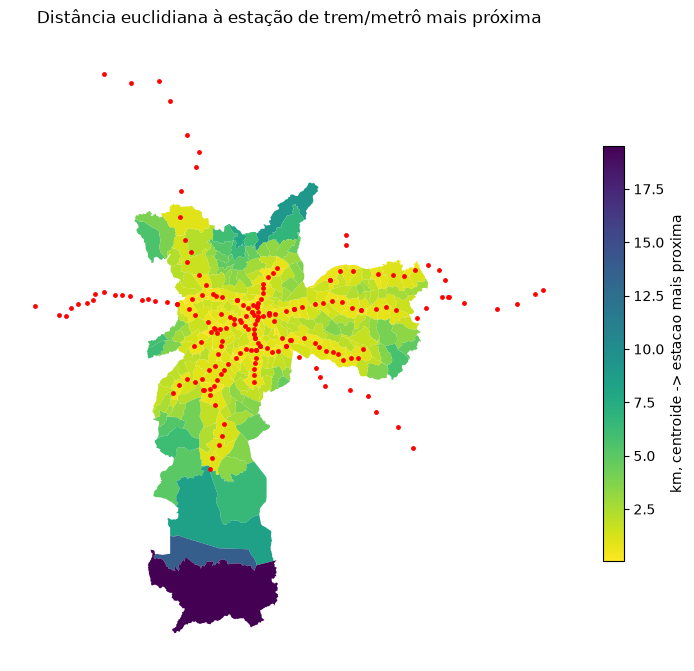

In [6]:
centroides = zonas.copy()
centroides["geometry"] = zonas.geometry.centroid

mais_proxima = (
    gpd.sjoin_nearest(centroides, estacoes[["estacao", "linha", "modo", "geometry"]], how="left", distance_col="dist_m")
    .sort_values(["NumeroZona", "dist_m"]).drop_duplicates("NumeroZona")      # empates: fica uma
    .set_index("NumeroZona")
)
dist = pd.DataFrame({
    "dist_estacao_eucl_km": mais_proxima["dist_m"] / 1000,
    "estacao_mais_proxima": mais_proxima["estacao"],
    "linha_mais_proxima": mais_proxima["linha"],
})
assert len(dist) == len(zonas) and dist["dist_estacao_eucl_km"].notna().all()

print(dist["dist_estacao_eucl_km"].describe().round(2).to_string())
print("\nzonas mais distantes de uma estacao:")
print(dist.join(zonas.set_index("NumeroZona")["NomeZona"]).nlargest(6, "dist_estacao_eucl_km")
      [["NomeZona", "dist_estacao_eucl_km", "estacao_mais_proxima"]].round(1).to_string())
print("\nzonas mais proximas:")
print(dist.join(zonas.set_index("NumeroZona")["NomeZona"]).nsmallest(4, "dist_estacao_eucl_km")
      [["NomeZona", "dist_estacao_eucl_km", "estacao_mais_proxima"]].round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 9))
zonas.merge(dist, left_on="NumeroZona", right_index=True).plot(
    column="dist_estacao_eucl_km", cmap="viridis_r", legend=True,
    legend_kwds={"label": "km, centroide -> estacao mais proxima", "shrink": 0.6}, ax=ax)
estacoes.plot(ax=ax, color="red", markersize=6)
ax.set_title("Distância euclidiana à estação de trem/metrô mais próxima")
ax.set_axis_off()
plt.show()

## Seção 4 — gravação

In [7]:
covariaveis = (
    zonas[["NumeroZona", "NomeZona"]].set_index("NumeroZona")
    .join(zona_cor).join(dist)
    .reset_index()
)
assert len(covariaveis) == 343
covariaveis.to_parquet(DIR_SAIDA / "covariaveis_zona.parquet", index=False)
estacoes.to_file(DIR_SAIDA / "estacoes_trilho.gpkg", driver="GPKG")

print(f"covariaveis_zona.parquet: {len(covariaveis)} zonas | sem pct_negros: {covariaveis['pct_negros'].isna().sum()}")
print(f"estacoes_trilho.gpkg: {len(estacoes)} paradas")
covariaveis.head()

covariaveis_zona.parquet: 343 zonas | sem pct_negros: 3
estacoes_trilho.gpkg: 198 paradas


,NumeroZona,NomeZona,pop_cor,pct_negros,dist_estacao_eucl_km,estacao_mais_proxima,linha_mais_proxima
0,1,Sé,3756.0,48.003195,0.194219,Sé,METRÔ L3
1,2,Parque Dom Pedro,3704.0,47.570194,0.452628,São Bento,METRÔ L1
2,3,Praça João Mendes,16143.0,44.706684,0.328739,Liberdade,METRÔ L1
3,4,Ladeira da Memória,24321.0,36.289626,0.490010,Anhangabaú,METRÔ L3
4,5,República,14688.0,34.538399,0.046001,República,METRÔ L3
